# 測定器の使い方(ボルテージフォロワ)

この講義で使う**測定器**(Arduino UNO R4 に MimicLab のスケッチを書き込んだもの)の使い方を覚えます。あわせて、いちばん簡単な回路である**ボルテージフォロワ**(入力をそのまま出力する回路)を Mimic で動かします。ほかの講義はすべて、この回の操作を使います。

> 準備:[講義の README](../README.md) の結線をして、測定器のスケッチ(MimicLab)を UNO R4 に書き込んでおきます。

## 測定器のしくみ

| 機能 | 中身 | 使い方(Python) |
|---|---|---|
| 信号発生器(FG) | UNO R4 の DAC(A0、12 bit、0〜5 V)。正弦波・方形波・三角波・直流 | `lab.fg.sine(周波数, 振幅, オフセット)` など |
| オシロ(2ch) | UNO R4 の ADC(14 bit、1 目盛り約 0.3 mV)。CH1 = A1(Mimic の入力)、CH2 = A2(Mimic の出力)。20 kHz を整数で割った速さで最大 4000 点 | `t, ch1, ch2 = lab.scope.capture(点数, fs=…)` |
| Mimic の操作 | Arduino のライブラリ(AnalogMimic)を通して設定 | `lab.mimic.…` |

- 信号発生器の**振幅**はピーク(中心から山まで)の電圧、**オフセット**は中心の電圧です(省略すると 2.5 V)。
- 取り込みは、信号発生器の波形の**位相 0(周期の始まり)から**始まります。何度取り込んでも同じところから始まるので、波形が止まって見えます。
- 講義で扱う周波数は 1 kHz 程度までです。20 kHz で取り込むので、それより速い信号は 1 周期あたりの点が少なくなります。

## 回路:ボルテージフォロワ

![ボルテージフォロワ](01_bypass/circuit.svg)

オペアンプの出力を反転入力(−)にそのまま戻した回路です。オペアンプは 2 つの入力(+ と −)の電圧が等しくなるように出力を動かすので、**出力 = 入力**になります。

$$V_\mathrm{out} = V_\mathrm{in}$$

何もしない回路に見えますが、入力からはほとんど電流を取らず(入力インピーダンスが高い)、出力からは電流を出せる(出力インピーダンスが低い)ので、弱い信号源と次の回路のあいだに入れる**緩衝(バッファ)**として使います。

## Mimic の設定

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.bypass()` | `mimic.setBypassDSP()` | ボルテージフォロワ(ゲイン 1) |

Mimic は入力を 200 kHz(5 µs ごと)で読み、計算して出力します。バイパスは計算をせず、読んだ値をそのまま出します。

## 準備:測定器につなぐ

`mimic=` のあとに Mimic のファームのビルド日が出ていれば、Mimic ともつながっています(`none` なら結線を確かめて `lab.mimic.begin()`)。

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

In [2]:
lab.mimic.bypass()

## 実験 1:入力と出力を重ねる

100 Hz、振幅 1 V の正弦波を入れて、20 kHz で 400 点(20 ms、2 周期)取り込みます。入力(CH1)と出力(CH2)がほぼ重なるはずです。

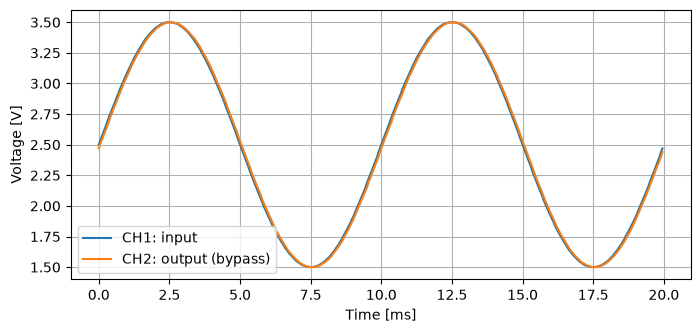

In [3]:
lab.fg.sine(100, 1.0)  # 100 Hz, 1 V peak, around 2.5 V
t, ch1, ch2 = lab.scope.capture(400)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (bypass)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

差(出力 − 入力)を数字で見ます。平均は直流のずれ(オフセットの誤差)、残りのばらつきは雑音や、出力が入力より少し遅れることによるものです。

In [4]:
diff = ch2 - ch1
print(f"mean of output - input: {diff.mean() * 1e3:+.1f} mV")
print(f"standard deviation    : {diff.std() * 1e3:.1f} mV")

mean of output - input: -0.4 mV
standard deviation    : 21.6 mV


## 実験 2:信号発生器の波形

正弦波(`sine`)、方形波(`square`)、三角波(`triangle`)、直流(`dc`)を順に出して、入力(CH1)を見ます。方形波は周期の前半が高い側、三角波は中心から上がり始めます。

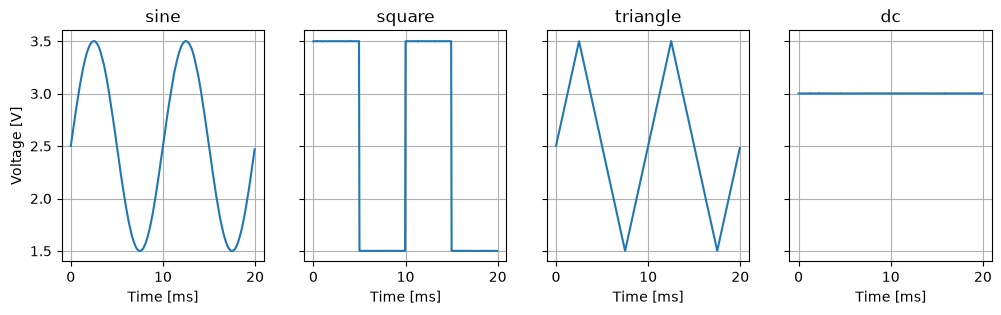

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
settings = [("sine", lambda: lab.fg.sine(100, 1.0)),
            ("square", lambda: lab.fg.square(100, 1.0)),
            ("triangle", lambda: lab.fg.triangle(100, 1.0)),
            ("dc", lambda: lab.fg.dc(3.0))]
for ax, (name, setup) in zip(axes, settings):
    setup()
    t, ch1, ch2 = lab.scope.capture(400)
    ax.plot(t * 1e3, ch1)
    ax.set_title(name)
    ax.set_xlabel("Time [ms]")
    ax.grid(True)
axes[0].set_ylabel("Voltage [V]")
plt.show()

## 実験 3:取り込みの設定

`fs` で取り込みの速さを変えられます(20000 Hz を整数で割った値)。点数 × 1/fs が取り込む時間です。ゆっくりした信号は fs を下げると長い時間を見られます。

`sync=False` にすると、位相 0 を待たずにすぐ取り込みます。取り込むたびに始まりの位置が変わります。

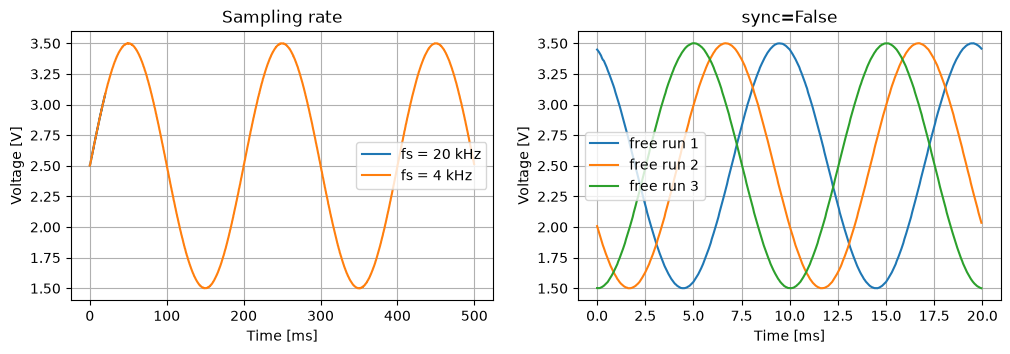

In [6]:
lab.fg.sine(5, 1.0)  # 5 Hz: a slow signal

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
t, ch1, ch2 = lab.scope.capture(400)             # 20 kHz: 20 ms
ax1.plot(t * 1e3, ch1, label="fs = 20 kHz")
t, ch1, ch2 = lab.scope.capture(2000, fs=4000)   # 4 kHz: 0.5 s
ax1.plot(t * 1e3, ch1, label="fs = 4 kHz")
ax1.set_title("Sampling rate")
ax1.set_xlabel("Time [ms]")
ax1.legend()

lab.fg.sine(100, 1.0)
for i in range(3):
    t, ch1, ch2 = lab.scope.capture(400, sync=False)
    ax2.plot(t * 1e3, ch1, label=f"free run {i + 1}")
ax2.set_title("sync=False")
ax2.set_xlabel("Time [ms]")
ax2.legend()
for ax in (ax1, ax2):
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
plt.show()

## 実験 4:出せる電圧の範囲

5 V の電源で動く回路は、0 V から 5 V の外の電圧を出せません。実際には電源の少し内側で頭打ちになります(Mimic の出力は 0 V と 5 V からそれぞれ約 0.1 V 内側まで)。振幅 2.4 V の正弦波(0.1〜4.9 V)を入れて、山と谷を拡大します。信号発生器(CH1)と Mimic(CH2)のどちらが先に頭打ちになるかも見てください。

input : 0.100 - 4.901 V
output: 0.101 - 4.900 V


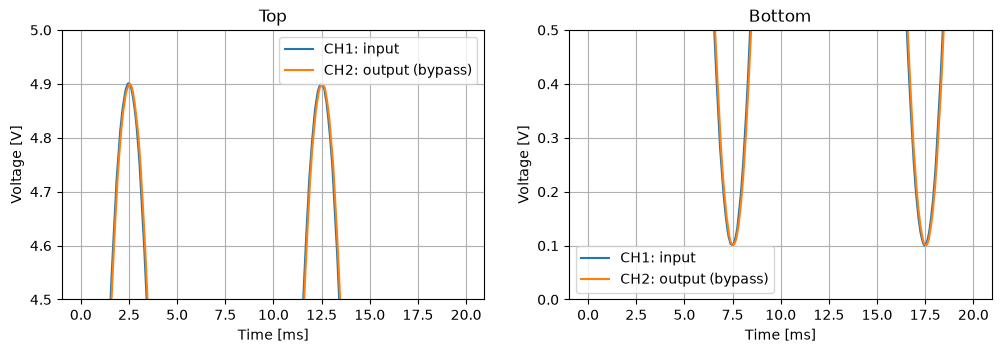

In [7]:
lab.fg.sine(100, 2.4)  # 0.1 - 4.9 V
t, ch1, ch2 = lab.scope.capture(400)
print(f"input : {ch1.min():.3f} - {ch1.max():.3f} V")
print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (lo, hi) in zip((ax1, ax2), [(4.5, 5.0), (0.0, 0.5)]):
    ax.plot(t * 1e3, ch1, label="CH1: input")
    ax.plot(t * 1e3, ch2, label="CH2: output (bypass)")
    ax.set_ylim(lo, hi)
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
    ax.legend()
ax1.set_title("Top")
ax2.set_title("Bottom")
plt.show()

講義では、ふつうは**中心 2.5 V、振幅 1 V 程度**の信号を使い、頭打ちにならないようにします。頭打ちのようすは、次の増幅回路の回でもう一度見ます。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 信号発生器を自由に動かす

波形、周波数、振幅、オフセットを 1 つずつ変えて、入力(CH1)を見ます。
<details><summary>ヒント</summary>

順に試してみましょう。

- `WAVE` を `"sine"` → `"square"` → `"triangle"`
- `FREQ` を 50 → 100 → 200(20 ms に入る周期の数が変わる)
- `AMP` を 0.5 → 1.0 → 1.5(山と谷の高さが変わる)
- `OFFSET` を 2.0 → 2.5 → 3.0(波形全体が上下に動く)

山は「オフセット + 振幅」、谷は「オフセット − 振幅」になります。

</details>

input: 1.499 - 2.499 V


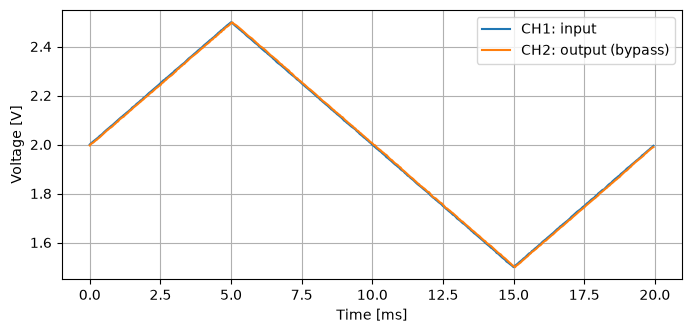

In [8]:
WAVE = "triangle"   # "sine", "square" or "triangle"
FREQ = 50           # frequency [Hz]
AMP = 0.5           # amplitude (peak) [V]
OFFSET = 2.0        # centre [V]

getattr(lab.fg, WAVE)(FREQ, AMP, OFFSET)
t, ch1, ch2 = lab.scope.capture(400)
print(f"input: {ch1.min():.3f} - {ch1.max():.3f} V")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (bypass)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. 頭打ちが始まる振幅を探す

中心 2.5 V の正弦波の振幅を少しずつ上げて、出力の山と谷がどこで止まるかを見ます。
<details><summary>ヒント</summary>

`AMP` を 2.0 → 2.2 → 2.4 → 2.5 と上げてみましょう。Mimic の出力は約 0.1〜4.9 V までなので、2.4 V あたりから山と谷が平らになります。信号発生器(CH1)も、電源の近くでは思った電圧まで出ないことがあります。

</details>

input : 0.500 - 4.503 V
output: 0.500 - 4.502 V


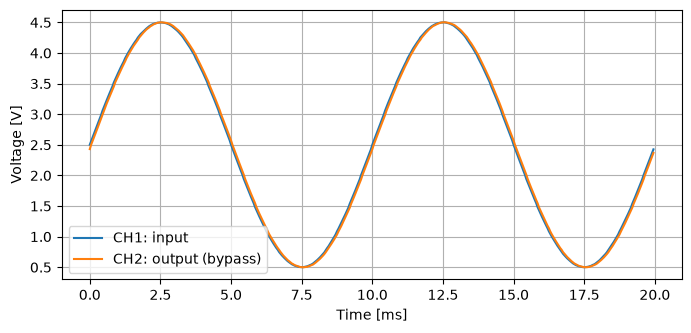

In [9]:
AMP = 2.0   # amplitude [V]

lab.fg.sine(100, AMP)
t, ch1, ch2 = lab.scope.capture(400)
print(f"input : {ch1.min():.3f} - {ch1.max():.3f} V")
print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (bypass)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 3. ちょうど 2 周期を取り込む

5 Hz の正弦波を、ちょうど 2 周期ぶん取り込むように、`FS` と `POINTS` を決めます(`FS` は 20000 を整数で割った値、`POINTS` は 4000 まで)。
<details><summary>ヒント</summary>

5 Hz の 1 周期は 0.2 s なので、2 周期は 0.4 s です。「点数 = 時間 × fs」なので、例えば `FS = 4000` なら `POINTS = 1600`、`FS = 5000` なら `POINTS = 2000` です。まず今の値(20 ms しか取り込めない)で実行してから、直してみましょう。

</details>

captured 0.020 s


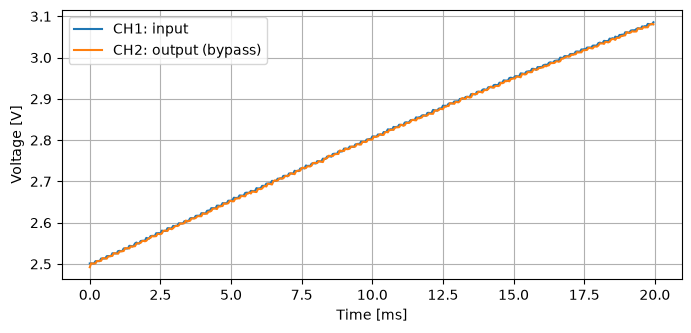

In [10]:
FS = 20000      # sampling frequency [Hz]: 20000 divided by an integer
POINTS = 400    # points (up to 4000)

lab.fg.sine(5, 1.0)
t, ch1, ch2 = lab.scope.capture(POINTS, fs=FS)
print(f"captured {POINTS / FS:.3f} s")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (bypass)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 4. プローブ(CH1)を付け替える

オシロは、ケーブルの先につながっている**実際の電圧**を測っています。CH1(A1)のケーブルを、オシロの「プローブ」として使ってみましょう。

CH1 のケーブルの**ブレッドボード側**を抜いて、ほかの場所に差し、下のセルを実行します。A0 から Mimic の AIN への線はそのままなので、Mimic には影響しません。

> **注意**
> - 0〜5 V の外の電圧には差さないでください。特に **VIN** は、外から電源をつなぐと 7〜12 V になることがあるので差さないでください。
> - ほかのピンどうしをショートさせないように気をつけてください。
> - 終わったら、**必ず元の列(A0 の列)に戻してください**。戻さないと、ほかの講義で CH1 が Mimic の入力を測れません。
<details><summary>ヒント</summary>

順に差してみましょう。

| 差す先 | 見えるもの |
|---|---|
| Arduino の **3.3V** | 約 3.3 V の平らな線 |
| Arduino の **GND** | 0 V |
| Arduino の **5V** | ほぼ 5 V(目盛りのいちばん上) |
| どこにも差さない(先を宙に浮かせる) | 50 Hz(東日本)か 60 Hz(西日本)の、電源の雑音(ハム)。0.1 秒に山が 5 個か 6 個 |
| 先の金属を**指でつまむ** | ハムに加えて、もっと大きく不規則にふらつく |
| 元の列(A0 の列)に戻す | 信号発生器の正弦波 |

何もつながっていない入力は、まわりの電線から交流の雑音(ハム)を拾います。指でつまむと、体が大きなアンテナになり、ハムのほかに静電気やいろいろな雑音も拾うので、さらに大きく不規則にふらつきます。

この ADC は、USB の 5 V を基準(目盛りのいちばん上)にして測っています。USB の電圧が 5 V より低い(例 4.8 V)と、3.3 V が少し高めに読めます。測定器も、自分の基準に対して測っているのです。

</details>

CH1: mean 2.561 V, min 0.883 V, max 4.144 V, peak to peak 3261 mV


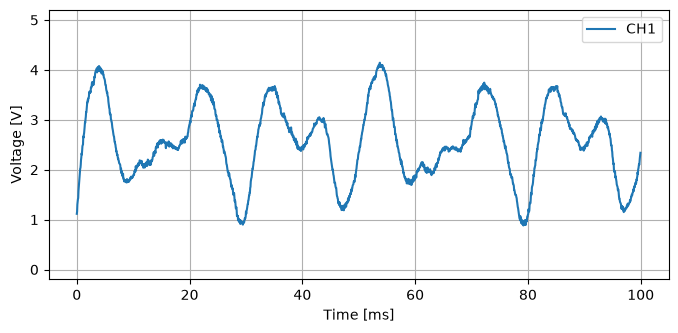

In [14]:
# Move the breadboard end of the CH1 (A1) wire, then run this cell
lab.fg.sine(100, 1.0)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
print(f"CH1: mean {ch1.mean():.3f} V, min {ch1.min():.3f} V, max {ch1.max():.3f} V, "
      f"peak to peak {(ch1.max() - ch1.min()) * 1e3:.0f} mV")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1")
ax.set_ylim(-0.2, 5.2)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## 測定器につなげるのは 1 つのノートブックだけ

測定器(Arduino)のシリアルポートは、1 つのプログラムしか開けません。ノートブックの最後では、必ず `lab.close()` で接続を閉じます。

JupyterLab では、ノートブックのタブを閉じても Python(カーネル)は動き続け、接続もつながったままです。閉じ忘れたまま別のノートブックで `MimicLab()` を実行すると、「ポートを開けません」というエラーになります。そのときは、

- 前のノートブックに戻って `lab.close()` を実行する、または
- JupyterLab の左の「実行中のカーネルとターミナル」から、前のノートブックのカーネルを止める

のどちらかをしてから、もう一度つなぎます。PlatformIO や Arduino IDE のシリアルモニタも閉じておきます。

## まとめ

- 信号発生器は `lab.fg`、オシロは `lab.scope.capture()`、Mimic は `lab.mimic` で操作する。取り込みは位相 0 から始まる。
- ボルテージフォロワは出力 = 入力の回路で、緩衝(バッファ)に使う。Mimic では `bypass()`。
- 5 V の電源の回路は、電源の少し内側までしか電圧を出せない。

最後に接続を閉じます(閉じないと、ほかのプログラムがシリアルポートを使えません)。

In [12]:
lab.fg.sine(100, 1.0)
lab.close()